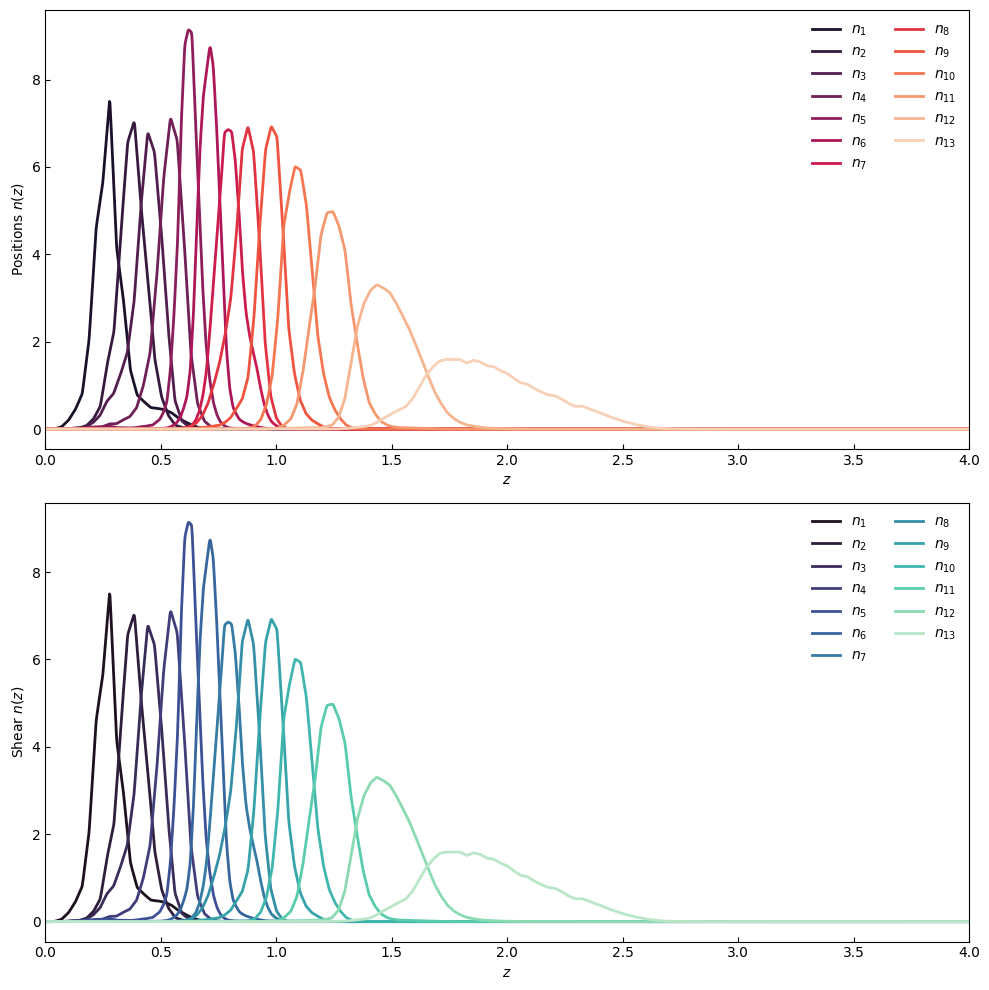

In [8]:
import euclidlib as el
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
import seaborn as sns

# cloelib imports
from cloelib.cosmology.camb_cosmology import CAMBBackground, CAMBLinearPerturbations, CAMBNonLinearPerturbations
from cloelib.cosmology.HMcode2020Emu_cosmology import HMemuLinearPerturbations, HMemuNonLinearPerturbations
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint
from cloelib.summary_statistics.angular_correlation_function_wigner import AngularCorrelationFunctionWigner

zs = np.linspace(1e-4, 3, 100)

# The arguments of the Background functions follow the cosmology.API
background = CAMBBackground(H0=70.0, 
                            Omega_cdm0=0.25, 
                            Omega_b0=0.05, 
                            w0=-1, 
                            wa=0, 
                            Omega_k0 = 0.0, 
                            ns = 0.96, 
                            As = 2e-9,
                            mnu = 0.06,
                            gamma_MG = 0.545,
                            N_mnu = 1)
linear_perturbations_emu = HMemuLinearPerturbations(background, zs)
nonlinear_perturbations_emu = HMemuNonLinearPerturbations(background, linear_perturbations_emu, zs, log10TAGN=7.8)
z, nz = el.photo.redshift_distributions('nzTabSPV3.fits')

def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)

# Plotting dndz
fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

20 20


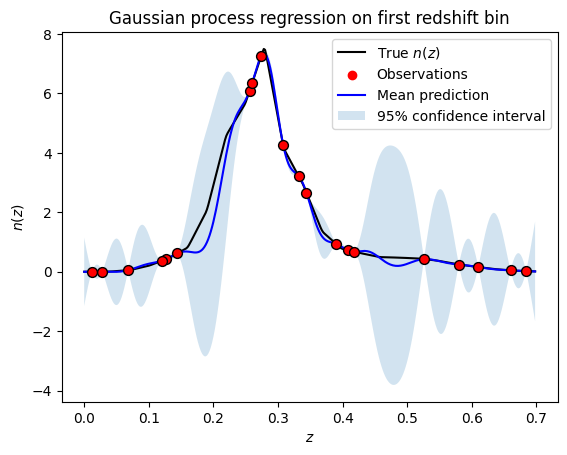

In [51]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

rng = np.random.RandomState(4)
z_range = (0, 0.7)
z_indces = np.where((z >= z_range[0]) & (z <= z_range[1]))[0]
z_1 = z[z_indces]
dndz_she_1 = dndz_she_norm[1][z_indces]
training_indices = rng.choice(np.arange(z_1.size), size=20, replace=False)
X_train, y_train = z_1[training_indices].reshape(-1,1), dndz_she_1[training_indices]
print(len(X_train), len(y_train))
plt.scatter(X_train, y_train, c='r', s=50, zorder=10, edgecolors=(0, 0, 0))

kernel =  C(1.0, (1e-3, 1e3)) * RBF(length_scale=2, length_scale_bounds=(1e-2, 1.0))
gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9)
gaussian_process.fit(X_train, y_train)
gaussian_process.kernel_

mean_prediction, std_prediction = gaussian_process.predict(z_1.reshape(-1,1), return_std=True)

plt.plot(z_1, dndz_she_1, c='black', label="True $n(z)$")
plt.scatter(X_train, y_train, c='red', label="Observations")
plt.plot(z_1, mean_prediction, c='blue', label="Mean prediction")
plt.fill_between(
    z_1.ravel(),
    mean_prediction - 1.96 * std_prediction,
    mean_prediction + 1.96 * std_prediction,
    alpha=0.2,
    label=r"95% confidence interval",
)
plt.legend()
plt.xlabel("$z$")
plt.ylabel("$n(z)$")
_ = plt.title("Gaussian process regression on first redshift bin")


z_centers: {1: array([0.08      , 0.63      , 0.27590319]), 2: array([0.184    , 0.56     , 0.3766136]), 3: array([0.192     , 0.61      , 0.44582912]), 4: array([0.27      , 0.706     , 0.54241966]), 5: array([0.468     , 0.77      , 0.62147485]), 6: array([0.558     , 0.886     , 0.70939806]), 7: array([0.638     , 0.994     , 0.79856575]), 8: array([0.642     , 1.02      , 0.86666092]), 9: array([0.758     , 1.186     , 0.97796899]), 10: array([0.914     , 1.302     , 1.09136353]), 11: array([1.036     , 1.476     , 1.24322479]), 12: array([1.244     , 1.822     , 1.47931666]), 13: array([1.416     , 2.562     , 1.89292361])}
n_at_centers: {1: array([0.        , 0.        , 7.38783932]), 2: array([0.        , 0.        , 6.89124298]), 3: array([0.        , 0.        , 6.75850344]), 4: array([0.        , 0.        , 7.08562136]), 5: array([0.        , 0.        , 9.13497829]), 6: array([0.        , 0.        , 8.66318512]), 7: array([0.        , 0.        , 6.83832932]), 8: array([0.

/tmp/ipykernel_26138/3455260542.py:6: DeprecationWarning: 'scipy.integrate.cumtrapz' is deprecated in favour of 'scipy.integrate.cumulative_trapezoid' and will be removed in SciPy 1.14.0
  cdf = integrate.cumtrapz(nz[key], z, initial=0)
/home/jipdebuck/cloelib-1/env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 0.01. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/jipdebuck/cloelib-1/env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Text(0, 0.5, '$n(z)$')

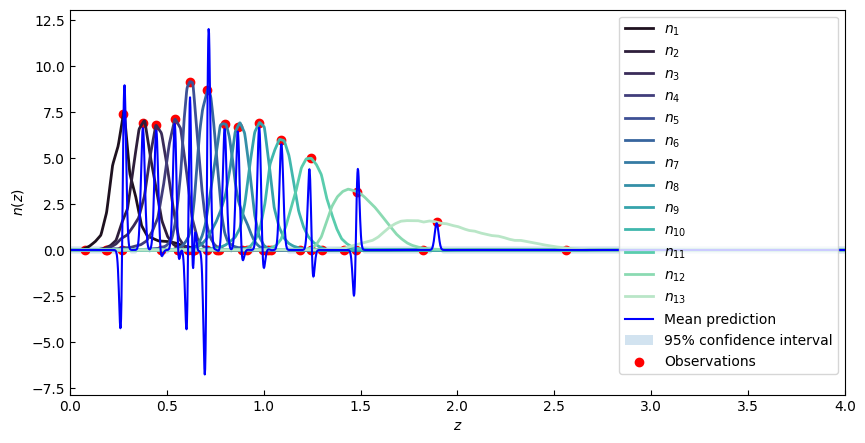

In [180]:
#Find redshift distribution using one training node per bin and correlation lengths'
cdfs = {}

for key in nz.keys():
    #cumulative integral of n(z)
    cdf = integrate.cumtrapz(nz[key], z, initial=0)
    
    #normalize so that CDF goes from 0 → 1
    cdf /= cdf[-1]
    
    cdfs[key] = cdf

z_centers = {}
for key in nz.keys():
    z_center = np.interp(0.5, cdfs[key], z)
    
    # store median in dictionary
    z_centers[key] = np.array([z_center])   # 1D array
    
    # edges: first and last z where n(z) > 0.1
    mask = nz[key] > 0.1
    z_edge_vals = np.array([z[mask][0], z[mask][-1]])  # left & right edges
    
    # combine edges and center into one array
    z_centers[key] = np.concatenate([z_edge_vals, z_centers[key]])

print('z_centers:', z_centers)  

n_at_centers = {}

for key in nz.keys():
    # nz[key] = array of n(z) values on a fine z grid
    # z_centers[key] = array of bin centers for this sample
    min_index = np.argmin(np.abs(z - z_centers[key][2]))
    
    # extract the n(z) value at that index
    n_center_value = np.array([nz[key][min_index]])  # make it 1D array
    
    # create zeros for baseline at edges
    n_zeros = np.zeros(2)  # left and right edges
    
    # concatenate zeros and n_center_value
    n_at_centers[key] = np.concatenate([n_zeros, n_center_value])

print('n_at_centers:', n_at_centers)
print('z_centers:', z_centers)

n_means = {}
for key in nz.keys():
    bin_indx = nz[key] > 0.1
    n_mean = np.mean(nz[key][bin_indx])
    n_means[key] = n_mean   


X = np.array([z_centers[key] for key in nz.keys()]).reshape(-1,1)
y = np.array([n_at_centers[key] for key in nz.keys()])
y = np.concatenate(y)
print(X, y)

sigma_obs = 0.02 * np.ones_like(y)
kernel = C(0.01, (0.001, 0.01)) * RBF(length_scale=0.5, length_scale_bounds=(0.01, 10))
gp = GaussianProcessRegressor(kernel=kernel, alpha=sigma_obs**2, n_restarts_optimizer=0, normalize_y=False)
gp.fit(X,y)

z_pred = np.linspace(0, 3, 500).reshape(-1,1)
y_pred, y_std = gp.predict(z.reshape(-1,1), return_std=True)

fig, axs = plt.subplots(1, 1, figsize=(10, 5))

# Customize tick parameters for both axes

axs.tick_params(axis='both', which='both', direction='in')

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs.plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)


axs.set_xlabel(r'$z$')
axs.set_ylabel(r'Shear $n(z)$')
axs.set_xlim(0, 4)
axs.legend(loc='right')




axs.plot(z, y_pred, c='blue', label="Mean prediction")
axs.fill_between(
    z.ravel(),
    y_pred - 1.96 * y_std,
    y_pred + 1.96 * y_std,
    alpha=0.2,
    label=r"95% confidence interval",
)
axs.scatter(X, y, c='red', label="Observations")
axs.legend()
axs.set_xlabel("$z$")
axs.set_ylabel("$n(z)$")

z_centers: {1: 0.2759031918083645, 2: 0.3766135980633325, 3: 0.4458291163626341, 4: 0.5424196599332396, 5: 0.62147485082995, 6: 0.7093980586687245, 7: 0.7985657465222972, 8: 0.8666609167150825, 9: 0.977968986175267, 10: 1.0913635348981672, 11: 1.2432247854803824, 12: 1.4793166613053534, 13: 1.892923607877304}
n_at_centers: {1: 7.3878393, 2: 6.891243, 3: 6.7585034, 4: 7.0856214, 5: 9.134978, 6: 8.663185, 7: 6.8383293, 8: 6.687738, 9: 6.9103985, 10: 5.9762745, 11: 4.9754233, 12: 3.169097, 13: 1.5132651}
z_centers: {1: 0.2759031918083645, 2: 0.3766135980633325, 3: 0.4458291163626341, 4: 0.5424196599332396, 5: 0.62147485082995, 6: 0.7093980586687245, 7: 0.7985657465222972, 8: 0.8666609167150825, 9: 0.977968986175267, 10: 1.0913635348981672, 11: 1.2432247854803824, 12: 1.4793166613053534, 13: 1.892923607877304}
0.0109
1**2 * RBF(length_scale=0.0109)


/tmp/ipykernel_26138/3496452862.py:5: DeprecationWarning: 'scipy.integrate.cumtrapz' is deprecated in favour of 'scipy.integrate.cumulative_trapezoid' and will be removed in SciPy 1.14.0
  cdf = integrate.cumtrapz(nz[key], z, initial=0)
/home/jipdebuck/cloelib-1/env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Text(0, 0.5, '$n(z)$')

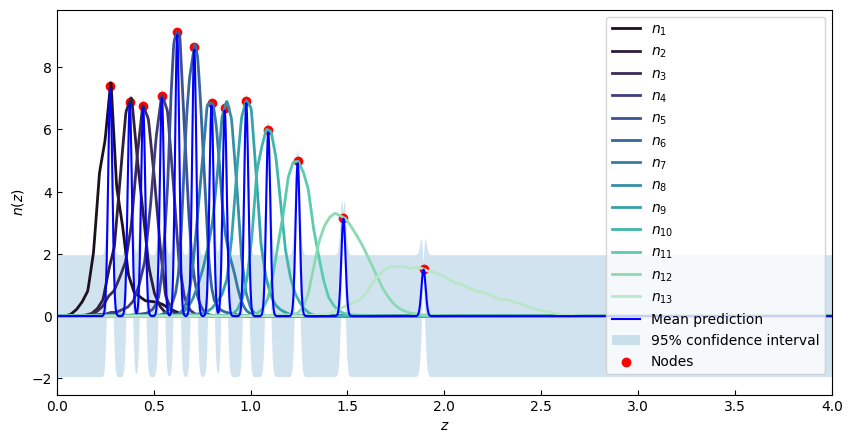

In [197]:
cdfs = {}

for key in nz.keys():
    #cumulative integral of n(z)
    cdf = integrate.cumtrapz(nz[key], z, initial=0)
    
    #normalize so that CDF goes from 0 → 1
    cdf /= cdf[-1]
    
    cdfs[key] = cdf

z_centers = {}
for key in nz.keys():
    z_center = np.interp(0.5, cdfs[key], z)
    
    # store median in dictionary
    z_centers[key] = z_center  # 1D array


print('z_centers:', z_centers)  

n_at_centers = {}

for key in nz.keys():
    # nz[key] = array of n(z) values on a fine z grid
    # z_centers[key] = array of bin centers for this sample
    min_index = np.argmin(np.abs(z - z_centers[key]))
    
    # extract the n(z) value at that index
    n_at_centers[key] = nz[key][min_index] # make it 1D array
    

print('n_at_centers:', n_at_centers)
print('z_centers:', z_centers)

n_means = {}
for key in nz.keys():
    bin_indx = nz[key] > 0.1
    n_mean = np.mean(nz[key][bin_indx])
    n_means[key] = n_mean   


X = np.array([z_centers[key] for key in nz.keys()]).reshape(-1,1)
y = np.array([n_at_centers[key] for key in nz.keys()])


l = 0.0109
print(l)
#sigma_obs = 0.02 * np.ones_like(y)
kernel = C(0.01, (0.001, 1)) * RBF(length_scale=l, length_scale_bounds=(1e-5, 1e5))
gp = GaussianProcessRegressor(kernel=kernel, alpha=0.01, n_restarts_optimizer=0, normalize_y=False)
gp.fit(X,y)
print(gp.kernel_)
z_pred = np.linspace(0, 3, 500).reshape(-1,1)
y_pred, y_std = gp.predict(z.reshape(-1,1), return_std=True)

fig, axs = plt.subplots(1, 1, figsize=(10, 5))

# Customize tick parameters for both axes

axs.tick_params(axis='both', which='both', direction='in')

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs.plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)


axs.set_xlabel(r'$z$')
axs.set_ylabel(r'Shear $n(z)$')
axs.set_xlim(0, 4)
axs.legend(loc='right')




axs.plot(z, y_pred, c='blue', label="Mean prediction")
axs.fill_between(
    z.ravel(),
    y_pred - 1.96 * y_std,
    y_pred + 1.96 * y_std,
    alpha=0.2,
    label=r"95% confidence interval",
)
axs.scatter(X, y, c='red', label="Nodes")
axs.legend(loc='upper right')
axs.set_xlabel("$z$")
axs.set_ylabel("$n(z)$")